# 02 - Can this experiment be trusted?
Before reading any result, an experiment has to pass trust checks. This notebook runs them on the simulated data, where we know
which experiments are planted with problems (see the README table). **Use the answer key only to judge the checks, never inside them.**

In [1]:
import os, sys, pathlib
root = pathlib.Path.cwd()
while not (root / "src").exists() and root != root.parent:
    root = root.parent
os.chdir(root); sys.path.insert(0, str(root))

import duckdb
import matplotlib.pyplot as plt
import pandas as pd
from src.config import DB_PATH
from src.warehouse.run_sql import run_query

pd.set_option("display.width", 160, "display.max_columns", 20)
con = duckdb.connect(str(DB_PATH), read_only=True)
print("project root:", root, "| database:", DB_PATH)
from scipy import stats
from src.experiments.novelty import decay_test, load as load_weekly, weekly_effects
from src.experiments.interaction import interaction_effect

project root: /content/drive/MyDrive/growth-experimentation-platform | database: /content/gep_work/experimentation.duckdb


## 1. Sample ratio mismatch (SRM)
The planned split is 50/50. A chi-square test on arm sizes flags assignment bugs. A failing experiment must not be analysed further.

In [2]:
srm = run_query(con, "srm_counts")
srm["srm_p_value"] = [stats.chisquare([c, t]).pvalue for c, t in zip(srm.control_users, srm.treatment_users)]
srm["verdict"] = ["FAIL: do not trust" if p < 0.001 else "ok" for p in srm.srm_p_value]
srm

,experiment_id,control_users,treatment_users,srm_p_value,verdict
0,exp_001,44893.0,45034.0,6.382188e-01,ok
1,exp_002,47446.0,47551.0,7.333518e-01,ok
2,exp_003,47426.0,47571.0,6.380339e-01,ok
3,exp_004,45243.0,44684.0,6.230914e-02,ok
4,exp_005,49908.0,50092.0,5.606616e-01,ok
5,exp_006,47354.0,40120.0,4.034991e-132,FAIL: do not trust
6,exp_007,47453.0,47544.0,7.678047e-01,ok
7,exp_008,49799.0,50201.0,2.036448e-01,ok
8,exp_009,50188.0,49812.0,2.344332e-01,ok


## 2. Do experiments that claim the same surface share users?

In [3]:
run_query(con, "overlapping_experiments")

,exp_a,exp_b,exclusive_group,shared_users
0,exp_001,exp_004,homepage_surface,89927


## 3. Interaction between the two overlapping experiments
Effect of exp_001 with and without exp_004 switched on for the same user. *Not significant does not prove the effects add*: it means the sample cannot tell.

In [4]:
cells = run_query(con, "experiment_interaction")
display(cells.drop(columns="orders_sq"))
pd.Series(interaction_effect(cells)).to_frame("value")

,variant_a,variant_b,users,orders,orders_per_user
0,control,control,22453,6810.0,0.30330
1,control,treatment,22440,7163.0,0.31921
2,treatment,control,22790,7569.0,0.33212
3,treatment,treatment,22244,8022.0,0.36064


,value
effect_A_when_B_on,0.041430
effect_A_when_B_off,0.028819
interaction,0.012611
ci_half,0.020334
p_value,0.224162
users,89927.000000


## 4. Novelty effect on exp_004
Weeks are counted from each user's own assignment. The lift by week shows whether the early lift fades; the trend test pairs each user with themselves because weeks are not independent.
Weeks where either arm has fewer than 500 users are dropped. A non-significant trend means *cannot tell at this sample size*, not *no novelty effect*.

,exposure_week,n_treat,n_ctrl,rate_treat,rate_ctrl,abs_effect,rel_lift,ci_half,p_value
0,1,43444,44057,0.1052,0.0971,0.0081,0.0838,0.0494,0.0005
1,2,42167,42766,0.0919,0.0838,0.0081,0.0966,0.0549,0.0003
2,3,40982,41513,0.0867,0.0829,0.0039,0.0465,0.0544,0.0865


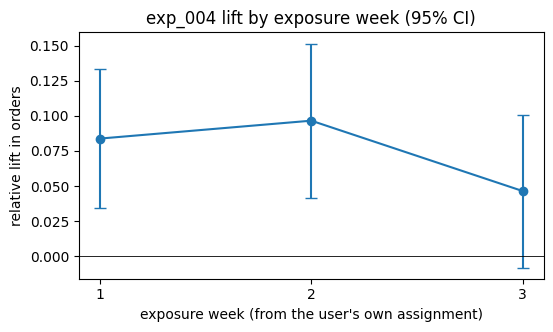

,value
weeks_used,"[1, 2, 3]"
users_in_all_weeks,82495
effect_change_per_week,-0.001992
ci_half,0.002961
p_value,0.187191


In [5]:
wk = load_weekly("exp_004")
eff = weekly_effects(wk)
display(eff.round(4))
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.errorbar(eff.exposure_week, eff.rel_lift, yerr=eff.ci_half, marker="o", capsize=4)
ax.axhline(0, color="k", lw=0.6); ax.set_xticks(eff.exposure_week)
ax.set_xlabel("exposure week (from the user's own assignment)"); ax.set_ylabel("relative lift in orders"); ax.set_title("exp_004 lift by exposure week (95% CI)")
plt.show()
pd.Series(decay_test(wk)).to_frame("value")

## Reading the results
Compare each check with the planted problems in the README. Anything the checks cannot resolve at 100k users is listed as a limit, not hidden.